# 01 - Load and explore the IndPenSim batch data

**Goal of this notebook:** download the IndPenSim dataset, keep only the process variables, save a compact copy, and take a first look at the 100 batches.

**About the data.** IndPenSim simulates a 100,000 L industrial penicillin fermentation (Goldrick et al., 2015 and 2019). It contains 100 fed-batch runs operated with different control strategies:

| Batches | Control strategy |
|---|---|
| 1-30 | Recipe-driven |
| 31-60 | Operator-controlled |
| 61-90 | Advanced Process Control (APC) using Raman |
| 91-100 | Contain process faults |

Source: [Mendeley Data, DOI 10.17632/pdnjz7zz5x](https://data.mendeley.com/datasets/pdnjz7zz5x), licence CC BY 4.0.

## 1. Setup

Mounting Google Drive

In [ ]:
USE_DRIVE = True  # set to False if you do not want to use Google Drive

from pathlib import Path

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        DATA_DIR = Path('/content/drive/MyDrive/indpensim')
    except ImportError:  # not running in Colab
        DATA_DIR = Path('data')
else:
    DATA_DIR = Path('data')

DATA_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = DATA_DIR / '100_Batches_IndPenSim.zip'
RAW_CSV = DATA_DIR / 'Mendeley_data' / '100_Batches_IndPenSim_V3.csv'
PROCESS_PARQUET = DATA_DIR / 'indpensim_process.parquet'
print('Data folder:', DATA_DIR.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data folder: /content/drive/MyDrive/indpensim


## 2. Download the data


In [ ]:
# @title
import zipfile
import requests

# (dataset id, version) to try, most recent first
MENDELEY_SOURCES = [('pdnjz7zz5x', 2), ('pdnjz7zz5x', 1), ('npt257bjxn', 1)]

def find_raw_csv():
    hits = sorted(DATA_DIR.rglob('*IndPenSim_V3*.csv'))
    return hits[0] if hits else None

def unzip_all():
    for zp in DATA_DIR.glob('*.zip'):
        print('Unzipping', zp.name)
        with zipfile.ZipFile(zp) as z:
            z.extractall(DATA_DIR)
    # the 'Download All' zip can contain another zip inside
    for zp in DATA_DIR.rglob('*.zip'):
        if zp.parent != DATA_DIR:
            with zipfile.ZipFile(zp) as z:
                z.extractall(zp.parent)

def list_mendeley_files(dataset_id, version):
    url = f'https://data.mendeley.com/public-api/datasets/{dataset_id}/files'
    r = requests.get(url, params={'folder_id': 'root', 'version': version}, timeout=60)
    r.raise_for_status()
    return r.json()

def download(url, dest):
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest, 'wb') as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)

def get_data():
    if PROCESS_PARQUET.exists():
        print('Clean file already cached - skipping download.')
        return
    if find_raw_csv() is None and any(DATA_DIR.rglob('*.zip')):
        unzip_all()
    if find_raw_csv() is not None:
        print('Raw CSV found:', find_raw_csv())
        return
    for dataset_id, version in MENDELEY_SOURCES:
        try:
            files = list_mendeley_files(dataset_id, version)
        except Exception as e:
            print(f'{dataset_id} v{version}: could not list files ({e})')
            continue
        print(f'{dataset_id} v{version}: files found:')
        for f in files:
            print('  -', f.get('filename'), f.get('size'))
        wanted = [f for f in files
                  if 'IndPenSim' in f.get('filename', '')
                  and f.get('filename', '').endswith(('.zip', 'V3.csv'))]
        for f in wanted:
            name = f['filename']
            link = f.get('content_details', {}).get('download_url')
            if not link:
                continue
            print('Downloading', name, '...')
            download(link, DATA_DIR / name)
        if wanted:
            unzip_all()
        if find_raw_csv() is not None:
            print('Raw CSV ready:', find_raw_csv())
            return
    raise RuntimeError('Automatic download failed. Please use the manual option '
                       'described above, then run this cell again.')

get_data()


Clean file already cached - skipping download.


## 3. Keep only the process variables

The raw CSV has about 40 process variables followed by about 2,200 Raman spectrum columns (named by wavenumber, starting at `2400`). For process monitoring we start with the process variables only, which keeps memory use small.

The raw file has **three labelling errors**, found during the checks of section 4:

1. The labels of the columns *Batch reference* and *2-PAT control* are swapped. The dataset authors fix this in their own notebook, and we do the same.
2. Despite its name, `Batch ID` is **not** a batch identifier: within each batch it grows from 0 to roughly 130,000-195,000. We do not use it. The correct identifier is `batch_id`; the code below checks it against the time resets every time the data is loaded.
3. Despite its name, `Fault flag` is **not** a fault label: it grows to roughly 180,000-195,000 in every group, including fault-free batches. The reliable fault label is `Fault reference` (see section 4.4).


In [ ]:
import numpy as np
import pandas as pd

def load_process_data(raw_csv):
    """Read only the process-variable columns of the IndPenSim CSV."""
    header = pd.read_csv(raw_csv, nrows=0).columns
    first_raman = header.get_loc('2400')
    process_cols = list(header[:first_raman])
    df = pd.read_csv(raw_csv, usecols=process_cols)
    # Fix the swapped labels (same fix as the dataset authors)
    df = df.rename(columns={
        '2-PAT control(PAT_ref:PAT ref)': 'Batch reference(Batch_ref:Batch ref)',
        'Batch reference(Batch_ref:Batch ref)': '2-PAT control(PAT_ref:PAT ref)',
    })
    df = df.rename(columns={'Batch reference(Batch_ref:Batch ref)': 'batch_id'})
    df['batch_id'] = df['batch_id'].astype(int)
    float_cols = df.select_dtypes('float64').columns
    df[float_cols] = df[float_cols].astype('float32')
    return df

def control_group(batch_id):
    if batch_id <= 30:
        return 'recipe'
    if batch_id <= 60:
        return 'operator'
    if batch_id <= 90:
        return 'APC (Raman)'
    return 'fault'

if PROCESS_PARQUET.exists():
    df = pd.read_parquet(PROCESS_PARQUET)
else:
    df = load_process_data(find_raw_csv())
    df['group'] = df['batch_id'].map(control_group)
    df.to_parquet(PROCESS_PARQUET, index=False)
    print('Saved clean copy to', PROCESS_PARQUET)

# Sanity check: the time restarts at 0 at the start of each batch,
# so batch_id must change exactly where the time resets.
batch_from_time = (df['Time (h)'].diff() < 0).cumsum() + 1
assert (df['batch_id'].values == batch_from_time.values).all(), \
    'batch_id does not match the time resets - check the column labels'
print('batch_id validated against time resets: OK')
print('Shape:', df.shape)


batch_id validated against time resets: OK
Shape: (113935, 40)


In [ ]:
print("shape of the dataframe:" ,df.shape, "\n")
df.head()

shape of the dataframe: (113935, 40) 



,Time (h),Aeration rate(Fg:L/h),Agitator RPM(RPM:RPM),Sugar feed rate(Fs:L/h),Acid flow rate(Fa:L/h),Base flow rate(Fb:L/h),Heating/cooling water flow rate(Fc:L/h),Heating water flow rate(Fh:L/h),Water for injection/dilution(Fw:L/h),Air head pressure(pressure:bar),...,Viscosity(Viscosity_offline:centPoise),Fault reference(Fault_ref:Fault ref),0 - Recipe driven 1 - Operator controlled(Control_ref:Control ref),1- No Raman spec,1-Raman spec recorded,batch_id,2-PAT control(PAT_ref:PAT ref),Batch ID,Fault flag,group
0,0.2,30,100,8,0.0000,30.118000,9.833500,0.0001,0,0.6,...,NaN,0,0,1,1,1,0,0.0,0.0,recipe
1,0.4,30,100,8,0.0000,51.221001,18.155001,0.0001,0,0.6,...,NaN,0,0,1,1,1,0,0.0,0.0,recipe
2,0.6,30,100,8,0.0000,54.301998,9.598200,0.0001,0,0.6,...,NaN,0,0,1,1,1,0,0.0,0.0,recipe
3,0.8,30,100,8,0.0000,37.816002,4.339500,0.0001,0,0.6,...,NaN,0,0,1,1,1,0,0.0,0.0,recipe
4,1.0,30,100,8,0.5181,18.908001,1.104500,0.0001,0,0.6,...,4.083,0,0,1,1,1,0,0.0,0.0,recipe


In [ ]:
print("batch_id groupby")
df.groupby('batch_id').size().describe()

batch_id groupby


,0
count,100.000000
mean,1139.350000
std,90.753454
min,835.000000
25%,1137.500000
50%,1150.000000
75%,1150.000000
max,1450.000000


In [ ]:
print("dataframe columns:")
df.columns

dataframe columns:


Index(['Time (h)', 'Aeration rate(Fg:L/h)', 'Agitator RPM(RPM:RPM)',
       'Sugar feed rate(Fs:L/h)', 'Acid flow rate(Fa:L/h)',
       'Base flow rate(Fb:L/h)', 'Heating/cooling water flow rate(Fc:L/h)',
       'Heating water flow rate(Fh:L/h)',
       'Water for injection/dilution(Fw:L/h)',
       'Air head pressure(pressure:bar)', 'Dumped broth flow(Fremoved:L/h)',
       'Substrate concentration(S:g/L)',
       'Dissolved oxygen concentration(DO2:mg/L)',
       'Penicillin concentration(P:g/L)', 'Vessel Volume(V:L)',
       'Vessel Weight(Wt:Kg)', 'pH(pH:pH)', 'Temperature(T:K)',
       'Generated heat(Q:kJ)',
       'carbon dioxide percent in off-gas(CO2outgas:%)',
       'PAA flow(Fpaa:PAA flow (L/h))',
       'PAA concentration offline(PAA_offline:PAA (g L^{-1}))',
       'Oil flow(Foil:L/hr)',
       'NH_3 concentration off-line(NH3_offline:NH3 (g L^{-1}))',
       'Oxygen Uptake Rate(OUR:(g min^{-1}))',
       'Oxygen in percent in off-gas(O2:O2  (%))',
       'Offline Penicil

## 4. Sanity checks

Before any modelling, four checks: the batches themselves, missing values, the batch groups, and the fault labels.

The four groups correspond to four ways of running the fermentation:

| Group | Batches | Who sets the process inputs | In practice |
|---|---|---|---|
| recipe | 1-30 | A fixed recipe | The same pre-defined profiles (sugar feed, aeration...) for every batch, with no reaction to what happens in the vessel |
| operator | 31-60 | Operators | People watch the measurements and adjust the inputs by hand |
| APC (Raman) | 61-90 | Advanced process control | A Raman probe estimates the broth composition online and an algorithm adjusts the inputs automatically |
| fault | 91-100 | As above, plus a fault | A process fault appears during the batch |

The first three groups are all **normal** batches, but they do not look alike: a change of control strategy is a legitimate change of operating conditions, which a monitor must not mistake for a fault.

### 4.1 Number and duration of batches

In [ ]:
print('Number of batches:', df['batch_id'].nunique())

batch_length = df.groupby('batch_id')['Time (h)'].max()
print('\nBatch duration (h):')
print(batch_length.describe())

Number of batches: 100

Batch duration (h):
count    100.000000
mean     227.869995
std       18.150694
min      167.000000
25%      227.500000
50%      230.000000
75%      230.000000
max      290.000000
Name: Time (h), dtype: float64


In [ ]:
# batches unusually short or long
print("unusually short \n", batch_length.sort_values(ascending=True).head(5))
print("\n")
print("unusually long \n", batch_length.sort_values(ascending=False).head(5))

unusually short 
 batch_id
67    167.0
5     179.0
15    181.0
17    188.0
75    192.0
Name: Time (h), dtype: float32


unusually long 
 batch_id
29    290.0
3     278.0
23    264.0
45    262.0
25    261.0
Name: Time (h), dtype: float32


In [ ]:
# Control strategy of the 5 shortest batches
df[df['batch_id'].isin([67, 5, 15, 17, 75])].groupby('group')['batch_id'].nunique()

,batch_id
group,
APC (Raman),2
recipe,3


In [151]:
# Control strategy of the 5 longest batches
df[df['batch_id'].isin([29, 3, 23, 45, 25])].groupby('group')['batch_id'].nunique()

,batch_id
group,
operator,1
recipe,4


Batch duration ranges from 167 h to 290 h (median 230 h).
7 of the 10 most extreme batches are recipe-driven, and none of them is a faulty batch (91-100).

Hypothesis: a fixed recipe does not correct for batch-to-batch variability in growth, so recipe batches end earlier or later, while operators and APC steer batches towards a standard trajectory. The box plot below tests it.

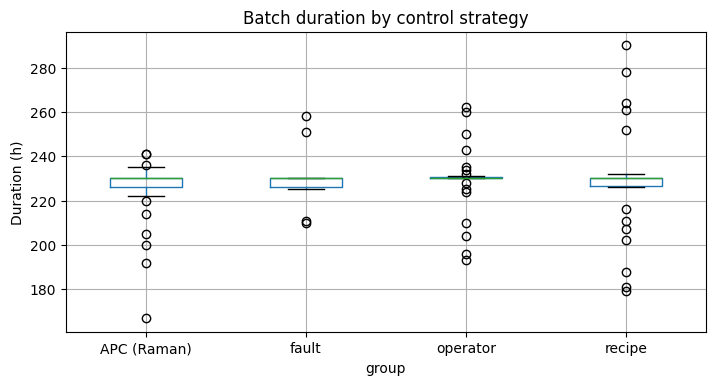

In [152]:
import matplotlib.pyplot as plt

# Batch duration by control strategy
batch_info = df.groupby('batch_id').agg(duration_h=('Time (h)', 'max'),
                                        group=('group', 'first'))
batch_info.boxplot(column='duration_h', by='group', figsize=(8, 4))
plt.suptitle('')
plt.title('Batch duration by control strategy')
plt.ylabel('Duration (h)')
plt.show()

Most batches last 226-230 h in every group (median 230 h), so the boxes are very narrow and differ only through their outliers. Recipe-driven batches show the widest range (179-290 h), which partly supports the hypothesis, but operator-controlled batches also vary a lot (193-262 h) and the shortest batch of all is an APC batch (167 h). The control strategy alone does not explain batch duration. Faulty batches (210-258 h) stay within the normal range: batch duration is not a fault indicator, so faults must be detected from the trajectories inside each batch.

### 4.2 Missing values

In [ ]:
# Share of missing values per column
missing = df.isna().mean().sort_values(ascending=False)
missing[missing > 0].round(3)

,0
Offline Biomass concentratio(X_offline:X(g L^{-1})),0.982
Offline Penicillin concentration(P_offline:P(g L^{-1})),0.982
NH_3 concentration off-line(NH3_offline:NH3 (g L^{-1})),0.982
Viscosity(Viscosity_offline:centPoise),0.982
PAA concentration offline(PAA_offline:PAA (g L^{-1})),0.982


Only the 5 offline laboratory measurements have missing values (98.2 % missing each). The remaining 1.8 % is about 20 samples per batch of ~1,140 rows, i.e. one lab sample roughly every 11 h, which is realistic for a plant. **No online sensor has gaps.** For the resilience tests (notebook 05) we will therefore create sensor faults and missing data ourselves.

### 4.3 Batches per control strategy

In [ ]:
# Number of batches per control strategy (expected: 30 / 30 / 30 / 10)
df.groupby('group')['batch_id'].nunique()

,batch_id
group,
APC (Raman),30
fault,10
operator,30
recipe,30


### 4.4 Fault labels

In [ ]:
# Are the two fault columns consistent with the batch groups?
fault_cols = ['Fault reference(Fault_ref:Fault ref)', 'Fault flag']
df.groupby('group')[fault_cols].agg(['min', 'max'])

Fault reference(Fault_ref:Fault ref)     Fault flag          
                                             min max        min       max
group                                                                    
APC (Raman)                                    0   0        0.0  180580.0
fault                                          0   1        0.0  178960.0
operator                                       0   0        0.0  190010.0
recipe                                         0   0        0.0  195340.0

`Fault reference` is the reliable fault label: it is 0 in every group except the fault group, where it switches from 0 to 1 **during** the batch. `Fault flag` is mislabelled (see section 3) and is not used.

Because the fault starts part-way through each faulty batch, we can measure how long a monitor takes to raise an alarm after the fault begins. The table below gives the reference fault timing used in notebook 04.

In [157]:
fr = 'Fault reference(Fault_ref:Fault ref)'
faulty = df[df['group'] == 'fault']
fault_true = faulty[faulty[fr] == 1]

fault_timing = pd.DataFrame({
    'fault_start_h': fault_true.groupby('batch_id')['Time (h)'].min(),
    'fault_end_h': fault_true.groupby('batch_id')['Time (h)'].max(),
    'batch_end_h': faulty.groupby('batch_id')['Time (h)'].max(),
    'share_faulty': faulty.groupby('batch_id')[fr].mean().round(2),
})
fault_timing

,fault_start_h,fault_end_h,batch_end_h,share_faulty
batch_id,,,,
91,20.0,214.0,258.0,0.16
92,80.0,160.0,230.0,0.11
93,70.0,90.0,210.0,0.10
94,20.0,110.0,230.0,0.06
95,20.0,211.0,211.0,0.18
96,70.0,90.0,230.0,0.09
97,20.0,214.0,225.0,0.18
98,80.0,160.0,230.0,0.11
99,20.0,110.0,251.0,0.06


The faults are intermittent: in batch 91, for instance, the fault window runs from 20 h to 214 h but the fault is active only 16 % of the time, in several episodes. Batches 93 and 96 have a single short fault (70-90 h). The same timing patterns repeat across batches (92/98, 93/96, 94/99/100, 91/97), which suggests a few fault types, each applied to several batches.

Consequences for evaluation (notebook 04): the detection delay is measured from the first fault episode; between episodes the batch is back to normal, so a good monitor should stop alarming; and short faults (93, 96) will be the hardest to detect.

## 5. First look: penicillin concentration over time

Each line is one batch, coloured by control strategy. Look for differences in the final titre between groups, and for batches that behave differently.

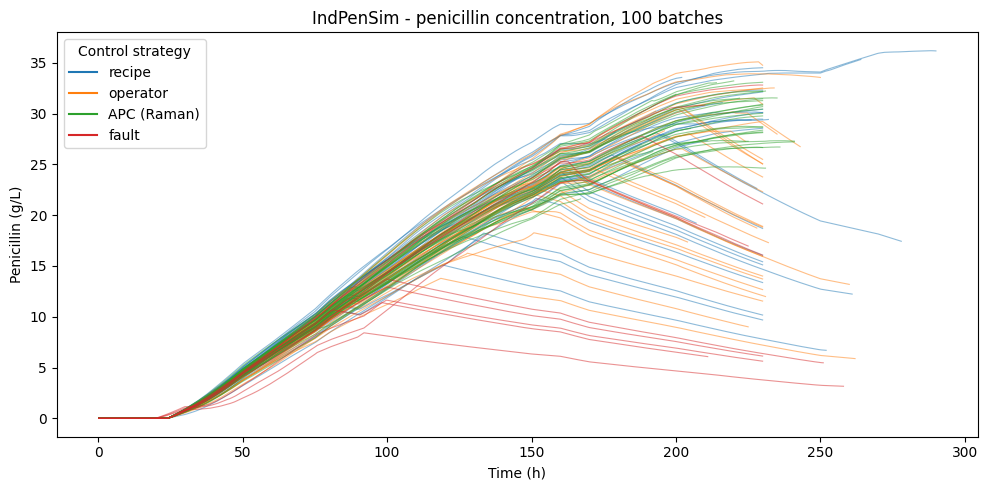

In [160]:
import matplotlib.pyplot as plt

colors = {'recipe': 'tab:blue', 'operator': 'tab:orange',
          'APC (Raman)': 'tab:green', 'fault': 'tab:red'}
y_col = 'Penicillin concentration(P:g/L)'

fig, ax = plt.subplots(figsize=(10, 5))
for (batch, group), g in df.groupby(['batch_id', 'group']):
    ax.plot(g['Time (h)'], g[y_col], color=colors[group], alpha=0.5, lw=0.8)
for group, c in colors.items():
    ax.plot([], [], color=c, label=group)
ax.set_xlabel('Time (h)')
ax.set_ylabel('Penicillin (g/L)')
ax.set_title('IndPenSim - penicillin concentration, 100 batches')
ax.legend(title='Control strategy')
plt.tight_layout()
plt.show()

In [169]:
y_col = 'Penicillin concentration(P:g/L)'

batch_summary = df.groupby('batch_id').agg(
    group=('group', 'first'),
    final_P=(y_col, 'last'),       # penicillin at the end of the batch
    max_P=(y_col, 'max'),          # highest penicillin reached
    duration_h=('Time (h)', 'max'),
)

comparison = batch_summary.groupby('group')[['final_P', 'max_P', 'duration_h']].agg(['mean', 'std'])
comparison

final_P                 max_P            duration_h           
                  mean        std       mean       std        mean        std
group                                                                        
APC (Raman)  29.406532   2.726507  29.418966  2.713894  224.666672  15.351813
fault        14.421339  10.972232  19.820059  9.122277  230.500000  14.938764
operator     21.508402   8.026443  26.309334  5.214281  229.233337  14.606761
recipe       24.315243   8.701588  27.560799  5.096026  228.833328  24.299969

APC has the most samples with the most Peniciline, [27 - 32 g/L more or less].

APC has the smallest dispersion meaning the group is more consitent between batchs.

Faults are not necessarly outlers.


## 6. Your turn

- [ ] Print `df.columns` and write, for each variable, whether it is a manipulated input, an online sensor or an offline lab measurement.
- [ ] Repeat the plot above for temperature, pH and dissolved oxygen.
- [ ] Compute the final penicillin concentration per batch and compare the four groups with a box plot.
- [ ] Plot batch 91 against a normal batch and describe what goes wrong.

Next notebook: build a "golden batch" from normal batches and a first monitoring chart.